Celda 1 — Montar Drive y verificar GPU



In [1]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi

Mounted at /content/drive
Tue Nov 24 23:00:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

Celda 2 — Descomprimir (con verificación de espacio)



In [2]:
import os, zipfile, shutil

# Verifica espacio libre antes de descomprimir
total, used, free = shutil.disk_usage('/content')
print(f"Espacio libre en /content: {free/1e9:.1f} GB")
assert free > 6e9, "Poco espacio libre, reinicia el runtime"

os.makedirs('/content/data', exist_ok=True)
with zipfile.ZipFile('/content/drive/MyDrive/yolov8_trees.zip', 'r') as z:
    z.extractall('/content/data')
!ls /content/data

Espacio libre en /content: 120.8 GB
data.yaml  images  labels


Celda 3 — Arreglar el path del data.yaml para Colab



In [3]:
from pathlib import Path
yaml_path = Path('/content/data/data.yaml')
lines = []
for line in yaml_path.read_text().splitlines():
    if line.startswith('path:'):
        lines.append('path: /content/data')
    else:
        lines.append(line)
yaml_path.write_text('\n'.join(lines) + '\n')
print(yaml_path.read_text())

path: /content/data
train: images/train
val: images/val
test: images/test

names:
  0: tree



Celda 4 — Instalar Ultralytics y fijar semillas



In [4]:
!pip install --force-reinstall -q numpy ultralytics

import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
print("Semillas fijadas. GPU:", torch.cuda.get_device_name(0))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
cuda-python 13.0.3 requires cuda-bindings~=13.0.3, but you have cuda-bindings 13.5.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.

Verificación rápida:
Antes de lanzar el entrenamiento, confirma que Ultralytics importa y ve la GPU:

In [1]:
import ultralytics, torch
print("Ultralytics:", ultralytics.__version__)
print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Ultralytics: 8.4.218
Torch: 2.15.0+cu132 | CUDA: True
GPU: Tesla T4


Celda 5 — Entrenamiento (fine-tuning YOLOv8n)



In [4]:
from ultralytics import YOLO

SEED = 42
model = YOLO('yolov8n.pt')   # preentrenado COCO -> fine-tuning (alcance mínimo)

results = model.train(
    data='/content/data/data.yaml',
    epochs=20,
    imgsz=640,
    batch=16,
    patience=10,             # early stopping -> D2
    seed=SEED,
    project='/content/drive/MyDrive/runs_trees',
    name='yolov8n_baseline',
    exist_ok=True,
    plots=True,
    val=True,
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.15.0+cu132 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, opset=None, optimize=False, op

Celda 6 — Evaluación en test (D1)



In [5]:
from ultralytics import YOLO
best = YOLO('/content/drive/MyDrive/runs_trees/yolov8n_baseline/weights/best.pt')

metrics = best.val(
    data='/content/data/data.yaml',
    split='test',
    imgsz=640,
    plots=True,
    project='/content/drive/MyDrive/runs_trees',
    name='eval_test',
    exist_ok=True,
)
print(f"mAP@0.5     = {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95= {metrics.box.map:.4f}")
print(f"Precision   = {metrics.box.mp:.4f}")
print(f"Recall      = {metrics.box.mr:.4f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.15.0+cu132 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 42.6±17.5 MB/s, size: 162.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/data/labels/test... 2532 images, 285 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2532/2532 457.3it/s 5.5s
val: New cache created: /content/data/labels/test.cache
WARNING ⚠️ Dataset images contain up to 432 objects (test=432), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=432 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━

Celda 7 — Copiar artefactos clave a Drive



In [6]:
import shutil, os
src = '/content/drive/MyDrive/runs_trees/yolov8n_baseline'
dst = '/content/drive/MyDrive/entrega_trees'
os.makedirs(dst, exist_ok=True)
for f in ['results.csv', 'results.png', 'confusion_matrix.png',
          'confusion_matrix_normalized.png', 'P_curve.png', 'R_curve.png', 'PR_curve.png']:
    p = os.path.join(src, f)
    if os.path.exists(p):
        shutil.copy(p, dst)
        print('copiado', f)
print('Listo ->', dst)

copiado results.csv
copiado results.png
copiado confusion_matrix.png
copiado confusion_matrix_normalized.png
Listo -> /content/drive/MyDrive/entrega_trees


Verificación

In [7]:
from pathlib import Path
from collections import Counter

lbl_dir = Path('/content/data/labels/train')
ws, hs = [], []
for f in list(lbl_dir.glob('*.txt'))[:2000]:
    for line in f.read_text().strip().splitlines():
        _, xc, yc, w, h = map(float, line.split())
        ws.append(w); hs.append(h)

import numpy as np
ws, hs = np.array(ws), np.array(hs)
print(f"bbox width  -> p50={np.percentile(ws,50):.3f}, p95={np.percentile(ws,95):.3f}, max={ws.max():.3f}")
print(f"bbox height -> p50={np.percentile(hs,50):.3f}, p95={np.percentile(hs,95):.3f}, max={hs.max():.3f}")
print(f"boxes con w>0.5 (mitad de imagen): {(ws>0.5).sum()} ({100*(ws>0.5).mean():.1f}%)")
print(f"boxes con w>0.3: {(ws>0.3).sum()} ({100*(ws>0.3).mean():.1f}%)")

bbox width  -> p50=0.061, p95=0.094, max=0.188
bbox height -> p50=0.061, p95=0.094, max=0.180
boxes con w>0.5 (mitad de imagen): 0 (0.0%)
boxes con w>0.3: 0 (0.0%)


In [8]:
from pathlib import Path
for s in ['train','val','test']:
    n_img = len(list(Path(f'/content/data/images/{s}').glob('*.jpg')))
    n_lbl = len(list(Path(f'/content/data/labels/{s}').glob('*.txt')))
    print(f"{s}: {n_img} imágenes, {n_lbl} labels")

train: 11816 imágenes, 11816 labels
val: 2532 imágenes, 2532 labels
test: 2532 imágenes, 2532 labels


In [9]:
from pathlib import Path
print(Path('/content/data/data.yaml').read_text())

path: /content/data
train: images/train
val: images/val
test: images/test

names:
  0: tree



Predicciones sobre train

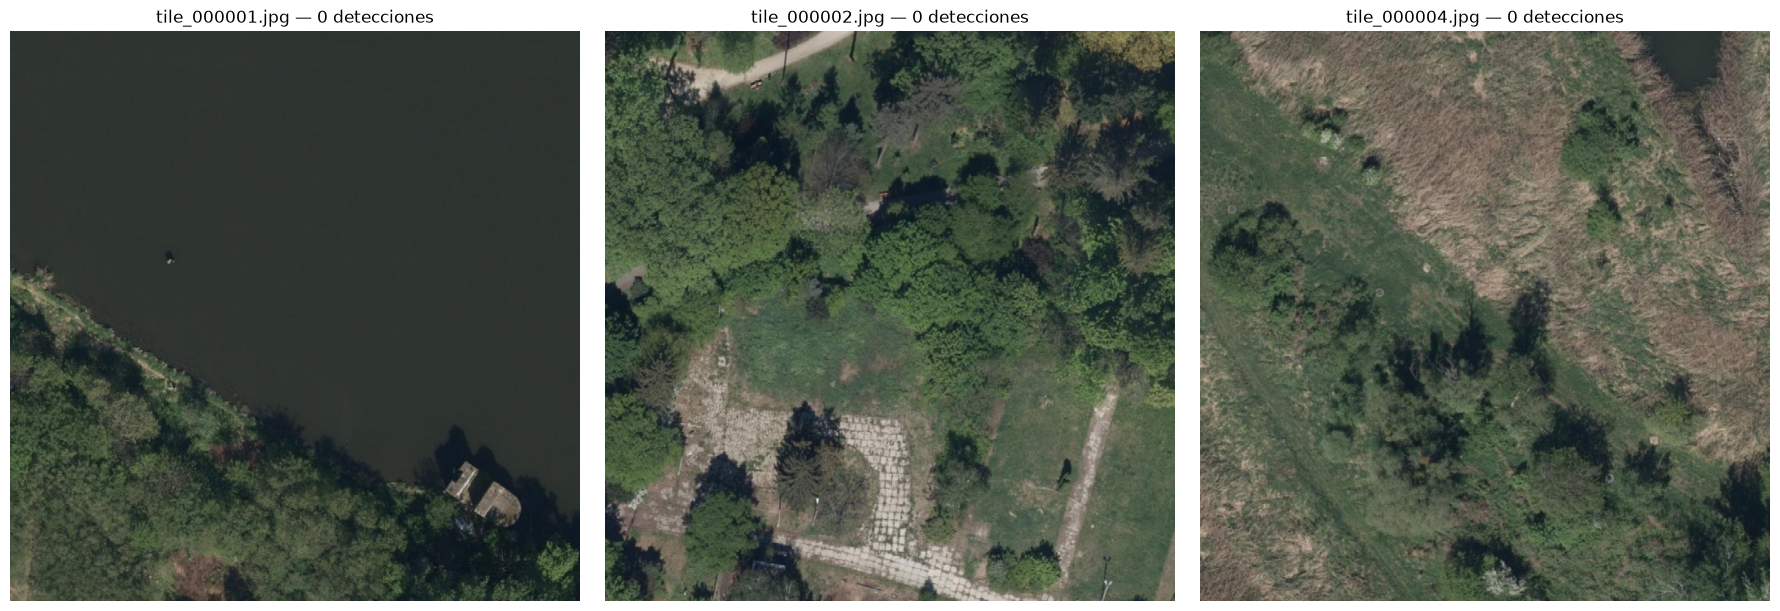

Confianza max en imagen 1: 0.164
Detecciones con conf>0.01: 300


In [10]:
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

model = YOLO('/content/drive/MyDrive/runs_trees/yolov8n_baseline/weights/best.pt')
imgs = sorted(Path('/content/data/images/train').glob('*.jpg'))[:3]

fig, axes = plt.subplots(1, 3, figsize=(18,6))
for ax, p in zip(axes, imgs):
    res = model.predict(str(p), conf=0.25, imgsz=640, verbose=False)[0]
    img = Image.open(p); ax.imshow(img)
    for b in res.boxes:
        x1,y1,x2,y2 = b.xyxy[0].tolist()
        ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color='lime', lw=2))
    ax.set_title(f"{p.name} — {len(res.boxes)} detecciones")
    ax.axis('off')
plt.tight_layout(); plt.show()

# Y el número que importa:
import numpy as np
res_all = model.predict(str(imgs[0]), conf=0.01, imgsz=640, verbose=False)[0]
print(f"Confianza max en imagen 1: {res_all.boxes.conf.max().item() if len(res_all.boxes) else 0:.3f}")
print(f"Detecciones con conf>0.01: {len(res_all.boxes)}")

In [11]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/runs_trees/yolov8n_baseline/results.csv')
print(df[['epoch','train/box_loss','val/box_loss','metrics/mAP50(B)','metrics/mAP50-95(B)']].tail(10).to_string(index=False))

 epoch  train/box_loss  val/box_loss  metrics/mAP50(B)  metrics/mAP50-95(B)
    11         2.65947       2.63193           0.07402              0.02119
    12         2.65434       2.62227           0.08925              0.02332
    13         2.64840       2.61065           0.07320              0.02133
    14         2.64043       2.62210           0.07981              0.02278
    15         2.62737       2.58349           0.08727              0.02466
    16         2.63069       2.63192           0.07592              0.02252
    17         2.62041       2.59714           0.08307              0.02389
    18         2.61265       2.58791           0.08918              0.02557
    19         2.60782       2.61702           0.09115              0.02613
    20         2.60537       2.59456           0.08933              0.02575


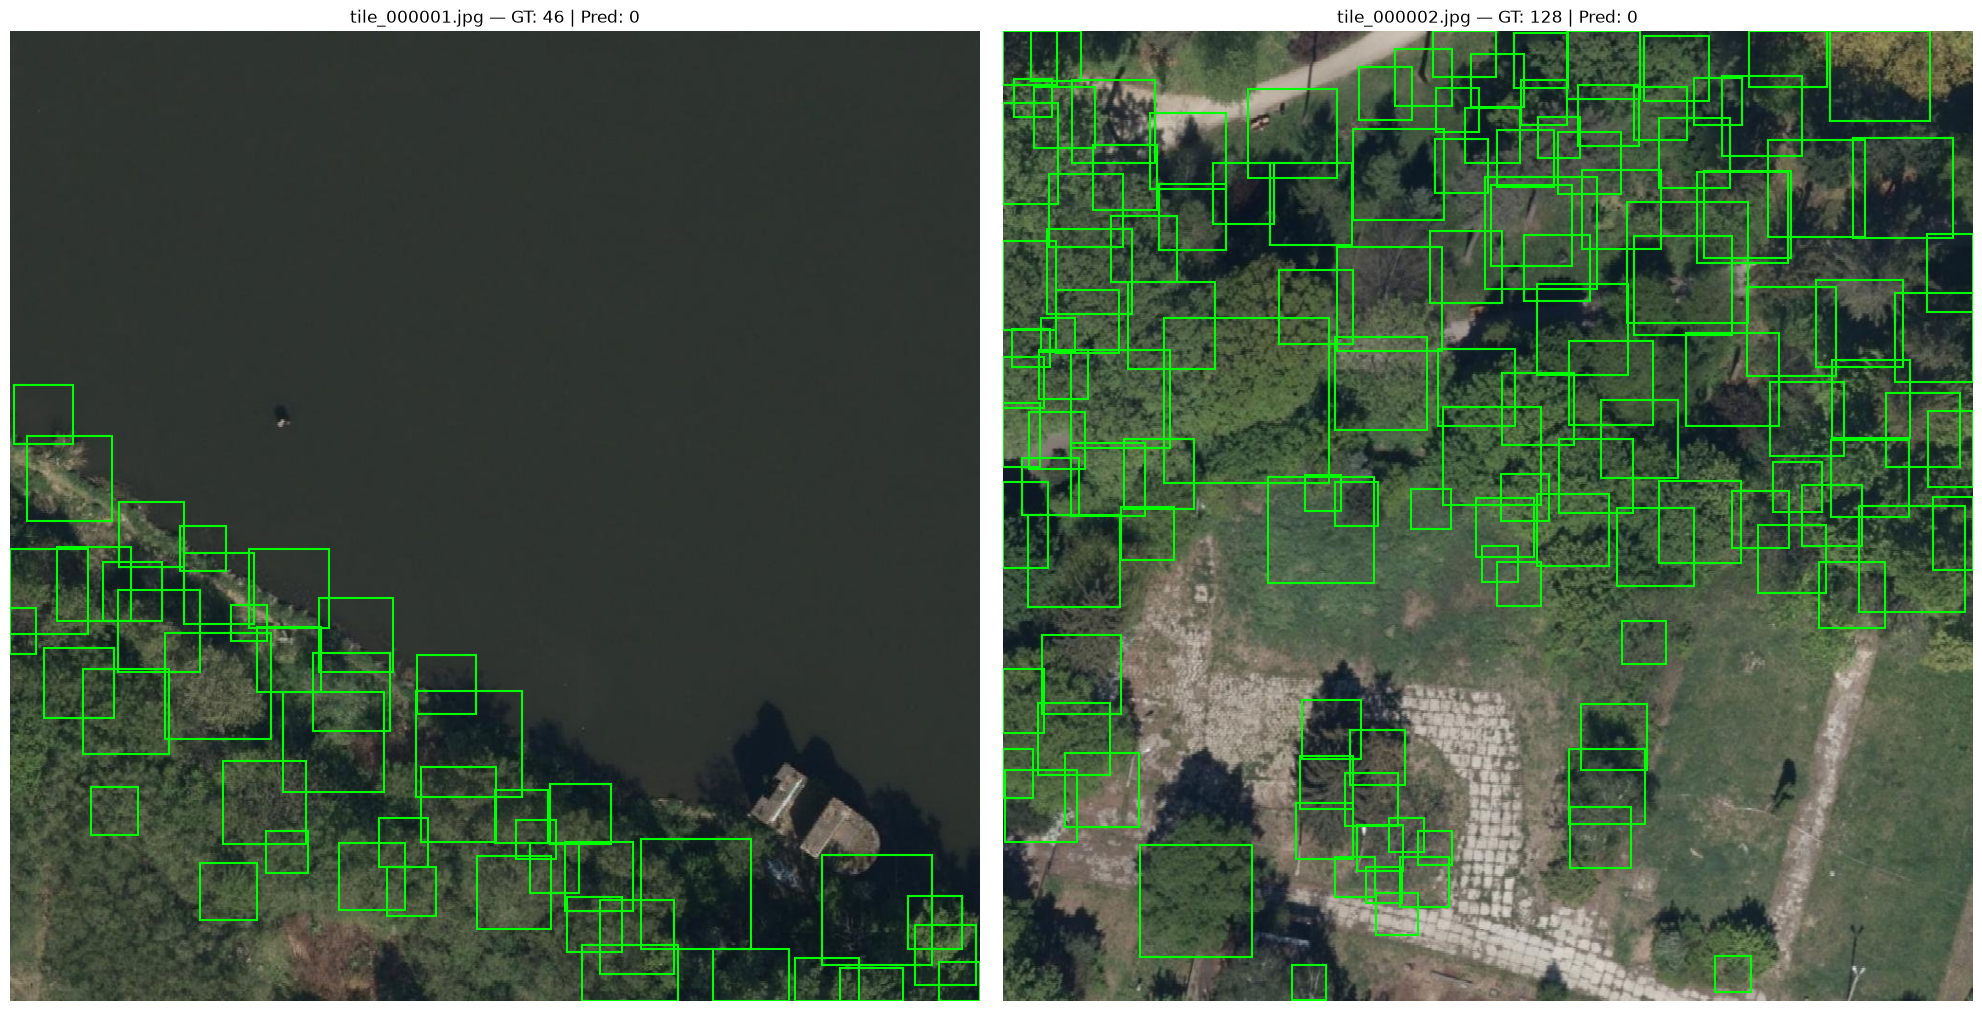

In [12]:
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

model = YOLO('/content/drive/MyDrive/runs_trees/yolov8n_baseline/weights/best.pt')
imgs = sorted(Path('/content/data/images/train').glob('*.jpg'))[:2]
lbls = [Path('/content/data/labels/train') / (p.stem + '.txt') for p in imgs]

fig, axes = plt.subplots(1, 2, figsize=(20,10))
for ax, p, l in zip(axes, imgs, lbls):
    img = Image.open(p); W,H = img.size
    ax.imshow(img)
    # Ground truth en VERDE
    for line in l.read_text().strip().splitlines():
        _, xc,yc,w,h = map(float, line.split())
        x1=(xc-w/2)*W; y1=(yc-h/2)*H
        ax.add_patch(patches.Rectangle((x1,y1), w*W, h*H, fill=False, color='lime', lw=1.5, label='GT'))
    # Predicción en ROJO
    res = model.predict(str(p), conf=0.25, imgsz=640, verbose=False)[0]
    for b in res.boxes:
        x1,y1,x2,y2 = b.xyxy[0].tolist()
        ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color='red', lw=1.5, label='Pred'))
    ax.set_title(f"{p.name} — GT: {len(l.read_text().strip().splitlines())} | Pred: {len(res.boxes)}")
    ax.axis('off')
plt.tight_layout(); plt.savefig('diagnostico_gt_vs_pred.png', dpi=110); plt.show()

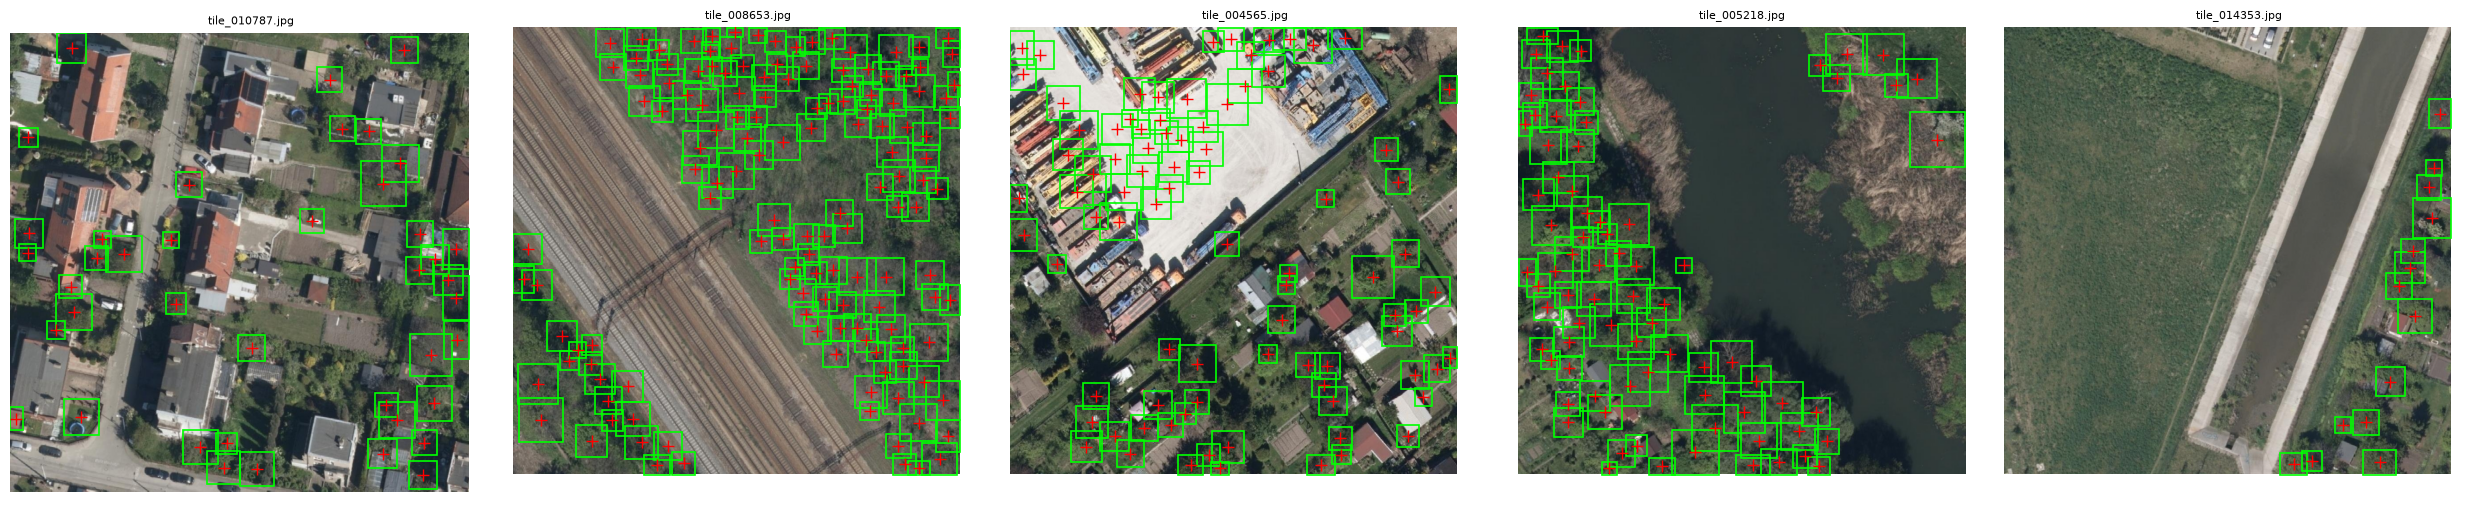

In [13]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
import numpy as np

# 5 tiles aleatorios, solo GT (verde) y un punto rojo en el centro del GT
imgs = sorted(Path('/content/data/images/train').glob('*.jpg'))
rng = np.random.default_rng(0)
sample = [imgs[i] for i in rng.choice(len(imgs), 5, replace=False)]

fig, axes = plt.subplots(1, 5, figsize=(25,5))
for ax, p in zip(axes, sample):
    img = Image.open(p); W,H = img.size
    ax.imshow(img)
    l = Path('/content/data/labels/train') / (p.stem + '.txt')
    for line in l.read_text().strip().splitlines():
        _, xc,yc,w,h = map(float, line.split())
        x1=(xc-w/2)*W; y1=(yc-h/2)*H
        ax.add_patch(patches.Rectangle((x1,y1), w*W, h*H, fill=False, color='lime', lw=1.2))
        ax.plot(xc*W, yc*H, 'r+', markersize=8)
    ax.set_title(p.name, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.savefig('gt_5_tiles.png', dpi=100); plt.show()